# Calculo de PG alto y bajo en República Dominicana.
### Los datos de temperatura maxima y minima diaria desde el año 2000 hasta el 2025 utilizados en los txt se obtuvieron de la pagina Infopave, se descargo la data de todas las temperaturas para republica dominicana en formalo .xlsx para hacer luego el analisis en excel de esa misma data.

In [247]:
import pandas as pd
import numpy as np
from math import log10
import matplotlib.pyplot as plt
from PIL import Image
from scipy.stats import norm

In [248]:
df_coord = pd.read_csv('estaciones_RD.txt', sep='\t')
df_coord['MERRA_ID'] = df_coord['MERRA_ID'].astype(int).astype(str)
display(df_coord)

,MERRA_ID,ELEVATION,LATITUDE,LONGITUDE
0,119983,1209,19.0,-71.250
1,119984,1212,19.0,-70.625
2,119985,117,19.0,-70.000
3,119986,34,19.0,-69.375
4,119987,-42,19.0,-68.750
5,118831,1067,18.0,-71.250
6,118835,-762,18.0,-68.750
7,119408,568,18.5,-70.625
8,120561,19,19.5,-70.000
9,121135,-1199,20.0,-71.250


In [249]:
#Datos de temperatura desde el archivo de texto separado por tabulaciones
df_temp_all = pd.read_csv('data_temp_RD.txt', sep='\t')
#Transformar el nombre de la estación (MERRA_ID) a texto
df_temp_all['MERRA_ID'] = df_temp_all['MERRA_ID'].astype(int).astype(str)
#Conversion de la columna de fecha a formato datetime
df_temp_all['DAY'] = pd.to_datetime(df_temp_all['DAY'])
display(df_temp_all.head())

,MERRA_ID,DAY,TEMP_MAX,TEMP_MIN,YEAR
0,119983,2025-12-01,26.3,17.1,2025
1,119983,2025-12-02,26.6,15.4,2025
2,119983,2025-12-03,26.4,16.0,2025
3,119983,2025-12-31,26.1,16.0,2025
4,119984,2025-12-01,24.8,16.8,2025


### Decidi utilizar esta ubicacion debido a que esta en la capital del pais en una de las carreteras principales.

In [250]:
lat_user, lon_user = (18.50825, -70.00591)
R = 0.98 # Confiabilidad deseada 
print(f'Latitud: {lat_user}, Longitud: { lon_user}, Confiabilidad: {R}')

Latitud: 18.50825, Longitud: -70.00591, Confiabilidad: 0.98


In [251]:
df_coord['DISTANCIA'] = ((df_coord['LATITUDE']-lat_user)**2 + (df_coord['LONGITUDE']-lon_user)**2)**0.5
df_coord = df_coord.sort_values(by = 'DISTANCIA')

estacion_ID = df_coord.iloc[0]['MERRA_ID']
estacion_Dist = df_coord.iloc[0]['DISTANCIA']
estacion_Lat = df_coord.iloc[0]['LATITUDE']
estacion_Lon = df_coord.iloc[0]['LONGITUDE']

print(f'Estación más cercana: {estacion_ID}, Distancia: {estacion_Dist:.4f}° Lat: {estacion_Lat:.4f}°, Lon:{estacion_Lon:.4f}')
display(df_coord.head(10))

Estación más cercana: 119409, Distancia: 0.0101° Lat: 18.5000°, Lon:-70.0000


,MERRA_ID,ELEVATION,LATITUDE,LONGITUDE,DISTANCIA
13,119409,60,18.5,-70.000,0.010148
2,119985,117,19.0,-70.000,0.491786
7,119408,568,18.5,-70.625,0.619145
15,119410,46,18.5,-69.375,0.630964
1,119984,1212,19.0,-70.625,0.790627
3,119986,34,19.0,-69.375,0.799916
8,120561,19,19.5,-70.000,0.991768
10,120560,314,19.5,-70.625,1.169120
11,120562,-2543,19.5,-69.375,1.175421
12,119407,125,18.5,-71.250,1.244117


In [252]:
# Filtrar los datos de temperatura para la estación seleccioanda 

df_temp = df_temp_all[df_temp_all['MERRA_ID'] == estacion_ID].copy()
                      
display(df_temp.head())  

,MERRA_ID,DAY,TEMP_MAX,TEMP_MIN,YEAR
159,119409,2025-12-04,29.4,23.1,2025
194,119409,2025-12-01,29.0,22.6,2025
197,119409,2025-12-02,29.4,22.6,2025
200,119409,2025-12-03,29.2,22.3,2025
345,119409,2025-12-05,29.1,23.1,2025


In [253]:
# 1. Cargar el archivo TXT
txt_path = 'data_temp_RD.txt'
df_temp = pd.read_csv(txt_path, sep='\t')

# 2. ASEGURAR QUE EL TIPO DE DATO COINCIDA (para evitar conflictos de texto/número)
df_temp['MERRA_ID'] = df_temp['MERRA_ID'].astype(int).astype(str)
estacion_ID_str = str(int(estacion_ID))

# 3. FILTRAR AUTOMÁTICAMENTE USANDO LA ESTACIÓN MÁS CERCANA CALCULADA ARRIBA
df_estacion = df_temp[df_temp['MERRA_ID'] == estacion_ID_str].copy()

# 4. Convertir la fecha a formato datetime
df_estacion['DAY'] = pd.to_datetime(df_estacion['DAY'])

# 5. Ordenar de forma descendente (del 2025 hacia abajo / fechas recientes arriba)
df_estacion = df_estacion.sort_values(by='DAY', ascending=False).reset_index(drop=True)

# 6. Calcular la temperatura media móvil de 7 días SOLAMENTE para esta estación
df_estacion['TEMP_MEAN_7D'] = (df_estacion['TEMP_MAX'].rolling(window=7, min_periods=7).mean())

# 7. Rellenar los valores nulos iniciales con 0
df_estacion['TEMP_MEAN_7D'] = df_estacion['TEMP_MEAN_7D'].fillna(0)

# 8. Extraer el año y formatear la fecha como texto para la visualización
df_estacion['YEAR'] = df_estacion['DAY'].dt.year
df_estacion['DAY'] = df_estacion['DAY'].dt.strftime('%Y-%m-%d')

# 9. Mostrar la tabla resultante
display(df_estacion.head(15))

,MERRA_ID,DAY,TEMP_MAX,TEMP_MIN,YEAR,TEMP_MEAN_7D
0,119409,2025-12-31,27.4,22.2,2025,0.000000
1,119409,2025-12-30,26.5,18.9,2025,0.000000
2,119409,2025-12-29,26.0,19.3,2025,0.000000
3,119409,2025-12-28,26.9,20.7,2025,0.000000
4,119409,2025-12-27,27.0,20.1,2025,0.000000
5,119409,2025-12-26,27.0,19.5,2025,0.000000
6,119409,2025-12-25,26.6,20.2,2025,26.771429
7,119409,2025-12-24,27.3,22.4,2025,26.757143
8,119409,2025-12-23,27.6,22.3,2025,26.914286
9,119409,2025-12-22,28.1,22.5,2025,27.214286


In [254]:
# 1. Cargar el archivo TXT manteniendo el orden original
txt_path = 'data_temp_RD.txt'
df_temp = pd.read_csv(txt_path, sep='\t')

# 2. CONVERTIR AMBOS A ENTERO (INT) PARA EVITAR CUALQUIER ERROR DE FILTRADO
df_temp['MERRA_ID'] = df_temp['MERRA_ID'].astype(int)
estacion_buscada = int(estacion_ID)

# 3. Filtrar exclusivamente los datos de la estación más cercana
df_estacion = df_temp[df_temp['MERRA_ID'] == estacion_buscada].copy()

# 4. Convertir la fecha a formato datetime y extraer el año
df_estacion['DAY'] = pd.to_datetime(df_estacion['DAY'])
df_estacion['YEAR'] = df_estacion['DAY'].dt.year

# 5. CALCULAR EL ROLLING DIRECTAMENTE EN EL ORDEN ORIGINAL DEL ARCHIVO
df_estacion['TEMP_MEAN_7D'] = (df_estacion['TEMP_MAX'].rolling(window=7, min_periods=7).mean())

# 6. Agrupar por año extrayendo el valor máximo de la media móvil y la mínima del aire
df_yearly = (df_estacion.groupby('YEAR').agg({'TEMP_MEAN_7D': 'max', 'TEMP_MIN': 'min'}).reset_index())

# 7. Renombrar la columna para que coincida exactamente con tu Excel
df_yearly = df_yearly.rename(columns={'TEMP_MEAN_7D': 'MAX 7 DAY AVERAGE'})

# 8. Ordenar de 2025 hacia abajo (del año más reciente al más antiguo)
df_yearly = df_yearly.sort_values(by='YEAR', ascending=False).reset_index(drop=True)

# 9. Mostrar la tabla final resultante (usando print o display asegurado)
display(df_yearly)

,YEAR,MAX 7 DAY AVERAGE,TEMP_MIN
0,2025,33.657143,18.9
1,2024,33.028571,18.8
2,2023,33.314286,18.4
3,2022,32.842857,19.5
4,2021,32.600000,18.9
5,2020,33.771429,19.8
6,2019,33.442857,19.9
7,2018,32.728571,18.6
8,2017,32.600000,17.5
9,2016,32.971429,19.8


In [255]:
# Calculo de resumen estadístico 

T_air_min = df_yearly['TEMP_MIN'].mean()
T_air_max = df_yearly['MAX 7 DAY AVERAGE'].mean()

sigma_air_min = df_yearly['TEMP_MIN'].std()
sigma_air_max = df_yearly['MAX 7 DAY AVERAGE'].std()

print(f'Temperatura Mínima del aire promedio (T_air_min): {T_air_min:.2f} °C')
print(f'Temperatura Máxima del aire promedio (T_air_max): {T_air_max:.2f} °C')
print(f'Desviación Estándar de T_air_min (sigma_air_min): {sigma_air_min:.2f} °C')
print(f'Desviación Estándar de T_air_max (sigma_air_max): {sigma_air_max:.2f} °C')

Temperatura Mínima del aire promedio (T_air_min): 18.87 °C
Temperatura Máxima del aire promedio (T_air_max): 33.06 °C
Desviación Estándar de T_air_min (sigma_air_min): 0.90 °C
Desviación Estándar de T_air_max (sigma_air_max): 0.51 °C


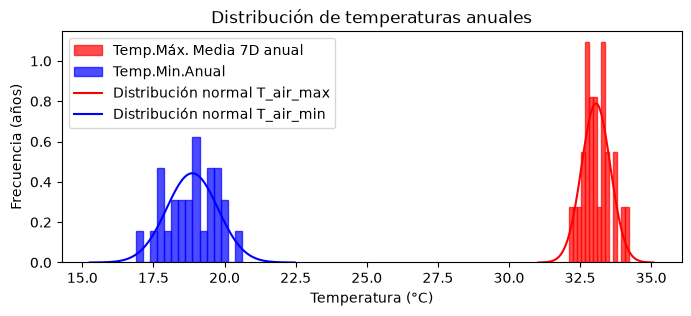

In [256]:
# Dibujar histogramas de las temperaturas altas y bajas anuales 

plt.figure(figsize=(8, 3))

plt.hist(df_yearly['MAX 7 DAY AVERAGE'], bins=15, alpha=0.7, color='red', edgecolor='red', label='Temp.Máx. Media 7D anual', density = 'True')
plt.hist(df_yearly['TEMP_MIN'], bins=15, alpha=0.7, color='blue', edgecolor='blue', label = 'Temp.Min.Anual', density = 'True')

# Dibujar histogramas de las temperaturas altas y bajas anuales 

x_air_max = np.linspace(T_air_max - 4*sigma_air_max, T_air_max + 4*sigma_air_max, 100)
y_air_max = norm.pdf(x_air_max, T_air_max, sigma_air_max)

x_air_min = np.linspace(T_air_min - 4*sigma_air_min, T_air_min + 4*sigma_air_min, 100)
y_air_min = norm.pdf(x_air_min, T_air_min, sigma_air_min)

plt.plot(x_air_max, y_air_max, color='red', label='Distribución normal T_air_max')
plt.plot(x_air_min, y_air_min, color='Blue', label='Distribución normal T_air_min')

plt.xlabel('Temperatura (°C)')
plt.ylabel('Frecuencia (años)')
plt.title('Distribución de temperaturas anuales')
plt.legend()
plt.savefig('histogramas_temp.png', dpi=300)
plt.show()

In [257]:
# Obtener otros datos necesarios 

H_max = 20 # mm
H_min = 0 # mm
z = norm.ppf(R)
print(f'Valor z para R={R}: {z:.4f}')

Valor z para R=0.98: 2.0537


In [258]:
# Cálculo de transformación de temperaturas del aire a temperaturas del pavimento en PG alto

T_pav_prom = 54.32 + 0.78*T_air_max - 0.0025*lat_user**2 - 15.14 * log10(H_max + 25)

sigma_pav_max = (9 + 0.61*sigma_air_max**2)**(0.5)

T_pav_alto = T_pav_prom + z * sigma_pav_max

print(f'Temperatura del pavimento promedio (T_pav_prom): {T_pav_prom:.2f} °C')
print(f'Desviación estándar de T_pav (sigma_pav_max): {sigma_pav_max:.2f} °C')
print(f'Temperatura del pavimento para R={R}: {T_pav_alto:.2f} °C')


Temperatura del pavimento promedio (T_pav_prom): 54.22 °C
Desviación estándar de T_pav (sigma_pav_max): 3.03 °C
Temperatura del pavimento para R=0.98: 60.43 °C


In [259]:
PG_max_com = [52, 58, 64, 70, 76, 82, 88, 94, 100]

filtered_PG = list(filter(lambda pg: pg>= T_pav_alto, PG_max_com))

PG_max_selected = filtered_PG[0]

print(f'PG Máximo seleccionado: PG {PG_max_selected}')

PG Máximo seleccionado: PG 64


In [260]:
# Cálculo de transformación de temperaturas del aire a temperaturas del pavimento en PG bajo

T_pav_prom_bajo = -1.56 + 0.72*T_air_min - 0.004*lat_user**2 + 6.26 * log10(H_min + 25)

sigma_pav_min = ( 4.4 + 0.52 * sigma_air_min**2)**(0.5)
z = -norm.ppf(R)
T_pav_bajo = T_pav_prom_bajo + z * sigma_pav_min

print(f'Temperatura del pavimento promedio (T_pav_prom_bajo): {T_pav_prom_bajo:.2f} °C')
print(f'Desviación estándar de T_pav (sigma_pav_min): {sigma_pav_min:.2f} °C')
print(f'Temperatura del pavimento para R={R}: {T_pav_bajo:.2f} °C')

Temperatura del pavimento promedio (T_pav_prom_bajo): 19.40 °C
Desviación estándar de T_pav (sigma_pav_min): 2.20 °C
Temperatura del pavimento para R=0.98: 14.89 °C


In [261]:
PG_min_com = [-10, -16, -22, -28, -34, -40, -46, -52, -58]

# Seleccionar el grado comercial cuyo valor sea el más cercano numéricamente a T_pav_bajo
PG_min_selected = min(PG_min_com, key=lambda pg: abs(pg - T_pav_bajo))

print(f"PG Mínimo seleccionado: PG {PG_min_selected}")

PG Mínimo seleccionado: PG -10


# Calculo de PG alto por método de modelo de daños por Ahuellamiento


In [262]:
import pandas as pd
from scipy.stats import norm

# --- 1. FILTRAR Y PREPARAR DATOS USANDO AUTOMÁTICAMENTE LA ESTACIÓN MÁS CERCANA ---
# Aseguramos que utilice la variable global calculada con la menor distancia (estacion_ID)
estacion_buscada = int(estacion_ID)

# Asegurar que el MERRA_ID en el dataframe sea entero para evitar conflictos de tipo
df_temp['MERRA_ID'] = df_temp['MERRA_ID'].astype(int)

df_estacion_cercana = df_temp[df_temp['MERRA_ID'] == estacion_buscada].copy()

# Convertir la columna 'DAY' a formato fecha explícitamente
df_estacion_cercana['DAY'] = pd.to_datetime(df_estacion_cercana['DAY'])

# Calcular temperatura media diaria y la comparación base (sobre 10°C)
df_estacion_cercana['TEMP_MEDIA'] = (df_estacion_cercana['TEMP_MAX'] + df_estacion_cercana['TEMP_MIN']) / 2
df_estacion_cercana['COMPARACION_BASE'] = (df_estacion_cercana['TEMP_MEDIA'] - 10).clip(lower=0)

# Extraer el año
df_estacion_cercana['YEAR'] = df_estacion_cercana['DAY'].dt.year

print('--- TABLA 1: DATOS DIARIOS Y COMPARACIÓN BASE (Primeras 10 filas) ---')
display(df_estacion_cercana[['DAY', 'TEMP_MAX', 'TEMP_MIN', 'TEMP_MEDIA', 'COMPARACION_BASE']].head(10))

# --- 2. TABLA RESUMEN ANUAL Y CÁLCULO DE DD ---
df_grados_dia_anual = (df_estacion_cercana.groupby('YEAR')['COMPARACION_BASE'].sum().reset_index(name='DD_ANUAL_TOTAL'))

print('\n--- TABLA 2: GRADOS-DÍA ACUMULADOS POR AÑO ---')
display(df_grados_dia_anual.head(10))

# Promedio anual de grados-día de la estación y conversión final del DD (dividido entre 1000)
promedio_grados_dia_anual = df_grados_dia_anual['DD_ANUAL_TOTAL'].mean()
DD = promedio_grados_dia_anual / 1000.0

# --- 3. APLICACIÓN DE ECUACIONES DE AHUELLAMIENTO (SUPERPAVE) ---
RD = 10.0  # Profundidad de rodera en mm
Lat = lat_user  # Latitud del proyecto
R = 0.5  # Confiabilidad deseada
Z = norm.ppf(R)  # Valor z de confiabilidad

# Ecuación 5.9: PG_H,d (Confiabilidad de 50%)
PG_H_d = 48.2 + 14 * DD - 0.96 * (DD**2) - 2 * RD

# Ecuación 5.10: Coeficiente de variación anual del PG (CVPG)
CVPG = 0.000034 * ((Lat - 20) ** 2) * (RD**2)

# Ecuación 5.11: PG_H,rel (Para la confiabilidad deseada Z)
PG_H_rel = PG_H_d + Z * (PG_H_d * CVPG / 100.0)

# --- 4. RESULTADOS FINALES ---
print('\n--- RESULTADOS DE DISEÑO SUPERPAVE (AHUELLAMIENTO) ---')
print(f'Estación más cercana utilizada -> ID: {estacion_ID}, Lat: {estacion_Lat}, Lon: {estacion_Lon}')
print(f'Valor de DD corregido (promedio anual / 1000): {DD:.4f}')
print(f'PG H,d (50% de confiabilidad): {PG_H_d:.2f} °C')
print(f'CVPG (Coeficiente de variación): {CVPG:.4f} %')
print(f'PG H,rel (Confiabilidad deseada {R*100:.0f}%): {PG_H_rel:.2f} °C')

--- TABLA 1: DATOS DIARIOS Y COMPARACIÓN BASE (Primeras 10 filas) ---


,DAY,TEMP_MAX,TEMP_MIN,TEMP_MEDIA,COMPARACION_BASE
159,2025-12-04,29.4,23.1,26.25,16.25
194,2025-12-01,29.0,22.6,25.80,15.80
197,2025-12-02,29.4,22.6,26.00,16.00
200,2025-12-03,29.2,22.3,25.75,15.75
345,2025-12-05,29.1,23.1,26.10,16.10
346,2025-12-06,28.9,22.6,25.75,15.75
347,2025-12-07,28.2,22.6,25.40,15.40
348,2025-12-08,28.8,23.0,25.90,15.90
349,2025-12-09,28.1,23.0,25.55,15.55
350,2025-12-10,28.2,22.6,25.40,15.40



--- TABLA 2: GRADOS-DÍA ACUMULADOS POR AÑO ---


,YEAR,DD_ANUAL_TOTAL
0,2000,6173.70
1,2001,6262.35
2,2002,6315.75
3,2003,6293.15
4,2004,6177.55
5,2005,6221.55
6,2006,6330.15
7,2007,6274.40
8,2008,6134.65
9,2009,6208.50



--- RESULTADOS DE DISEÑO SUPERPAVE (AHUELLAMIENTO) ---
Estación más cercana utilizada -> ID: 119409, Lat: 18.5, Lon: -70.0
Valor de DD corregido (promedio anual / 1000): 6.2379
PG H,d (50% de confiabilidad): 78.18 °C
CVPG (Coeficiente de variación): 0.0076 %
PG H,rel (Confiabilidad deseada 50%): 78.18 °C


In [263]:
# --- SELECCIÓN DEL GRADO COMERCIAL SUPERPAVE (ALTAS TEMPERATURAS) ---

# 1. Lista estándar de grados comerciales Superpave altos
PG_max_com = [52, 58, 64, 70, 76, 82, 88, 94, 100]

# 2. Filtrar los grados comerciales que cumplen con ser mayores o iguales al calculado (PG_H_rel)
filtered_PG_max = list(filter(lambda pg: pg >= PG_H_rel, PG_max_com))

# 3. Seleccionar el grado comercial correspondiente
if filtered_PG_max:PG_max_selected = (filtered_PG_max[0])  # Toma el valor comercial inmediatamente superior/cercano
else:PG_max_selected = PG_max_com[-1]  # Valor por defecto máximo si excede la lista

# 4. Mostrar el resultado final
print(f"Temperatura de diseño (PG_H_rel): {PG_H_rel:.2f} °C")
print(f"PG Máximo comercial seleccionado: PG {PG_max_selected}")

Temperatura de diseño (PG_H_rel): 78.18 °C
PG Máximo comercial seleccionado: PG 82


In [264]:
import pandas as pd

# 1. Amarrar los valores directamente a los resultados reales de los cálculos previos
pg_clasico_calculado = (T_pav_alto)  # O usa tu variable de temperatura del método clásico)
pg_ahuellamiento_calculado = (PG_H_rel)  # Valor real obtenido de la ecuación de ahuellamiento (apx. 78.18 °C)

# 2. Función lógica para seleccionar el grado comercial Superpave estándar (saltos de 6°C)
def obtener_pg_comercial(valor):
  if valor <= 58:
    return 'PG 58'
  elif valor <= 64:
    return 'PG 64'
  elif valor <= 70:
    return 'PG 70'
  elif valor <= 76:
    return 'PG 76'
  elif valor <= 82:
    return 'PG 82'
  else:
    return 'PG 88'


# 3. Asignación automática de los grados comerciales según el resultado real
pg_comercial_clasico = obtener_pg_comercial(pg_clasico_calculado)
pg_comercial_ahuellamiento = obtener_pg_comercial(pg_ahuellamiento_calculado)

# Si prefieres mostrar explícitamente el grado comercial numérico exacto que arroja la corrida (ej. PG 78):
# (Puedes descomentar la línea de abajo si tu normativa permite reportar el valor exacto)
# pg_comercial_ahuellamiento = f"PG {int(round(pg_ahuellamiento_calculado / 2) * 2)}" # O ajustado a tu preferencia

# 4. Construir el DataFrame de comparación vinculando las variables dinámicas
data_comparacion = {'Método de Diseño': ['Transformación de Tº Aire a Pavimento (Clásico/Estadístico)','Modelo de Daños por Ahuellamiento (Ecs. 5.9 - 5.11)',],'PG Alto Calculo (°C)': [
round(pg_clasico_calculado, 2),round(pg_ahuellamiento_calculado, 2),],'PG Alto Comercial Seleccionado': [pg_comercial_clasico,pg_comercial_ahuellamiento,],}

df_comparacion = pd.DataFrame(data_comparacion)

# 5. Mostrar la tabla comparativa final
print('--- TABLA COMPARATIVA CORREGIDA: MÉTODOS DE PG ALTO ---')
display(df_comparacion)

--- TABLA COMPARATIVA CORREGIDA: MÉTODOS DE PG ALTO ---


,Método de Diseño,PG Alto Calculo (°C),PG Alto Comercial Seleccionado
0,Transformación de Tº Aire a Pavimento (Clásico...,60.43,PG 64
1,Modelo de Daños por Ahuellamiento (Ecs. 5.9 - ...,78.18,PG 82


### El método de los 7 días y el modelo de ahuellamiento se diferencian en su enfoque climático, concepto de daño y resultados. El método clásico utiliza la temperatura máxima promedio móvil de 7 días para evaluar un pico térmico extremo y aislado, lo que arrojó un **PG 64**. En contraste, el modelo de ahuellamiento utiliza el factor Grado-Día ($DD$) anual acumulado sobre $10^\circ\text{C}$ junto con la latitud y la rodera admisible, representando el daño como la deformación permanente acumulada por el tráfico a lo largo del tiempo. Por esta razón, el modelo de ahuellamiento evalúa el comportamiento energético a largo plazo y resulta más exigente y conservador con un **PG 76**.